   iid  iid_o  gender  gender_o  age  age_o  \
0  194    214       0         1   24     23   
1  195    214       0         1   27     23   
2  196    214       0         1   25     23   
3  197    214       0         1   24     23   
4  198    214       0         1   23     23   

                                    race                       race_o  \
0            European/Caucasian-American  European/Caucasian-American   
1            European/Caucasian-American  European/Caucasian-American   
2  Asian/Pacific Islander/Asian-American  European/Caucasian-American   
3                                  Other  European/Caucasian-American   
4  Asian/Pacific Islander/Asian-American  European/Caucasian-American   

   importance_race  importance_race_o  ...  importance_fun  \
0                9                  6  ...           16.00   
1                3                  6  ...           19.23   
2                1                  6  ...           15.69   
3                2            

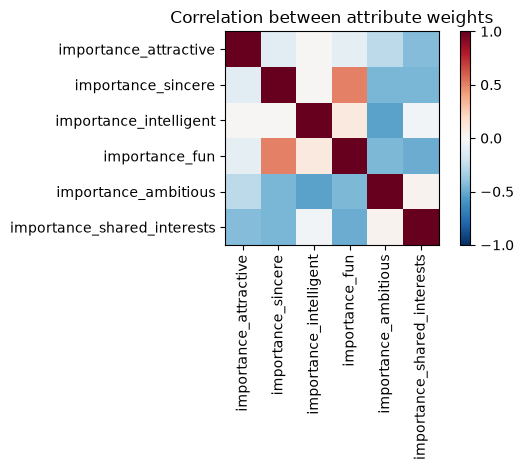

-0.2645578035483034
importance_attractive          0.229241
importance_sincere             0.298538
importance_intelligent         0.344912
importance_fun                 0.186125
importance_ambitious          -0.408063
importance_shared_interests   -0.267229
dtype: float64
0.3223797213489478


In [ ]:
#load the data and load the correct packages:project set up.

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/speed-dating.csv")
# put your own path here in this case its a relative path to the data folder in the project directory.

## question 1: 
# step 1 list variables, 
print(df.head())
print(df.columns)
#step 2
#What is the average number of matches per participant?
matches_per_person = df.groupby("iid")["match"].sum()
print(matches_per_person.mean())
# group the data by participant id (iid) and sum the matches for each participant, 
# then calculate the mean of those sums to get the average number of matches per participant.

## question 2:

# Step 1: list the six attributes
attributes = ["importance_attractive", "importance_sincere", "importance_intelligent",
              "importance_fun", "importance_ambitious", "importance_shared_interests"]
print(attributes)

# Step 2: average weight of each attribute by gender, top 3
means = df.groupby("gender")[attributes].mean()

print(means.loc[0].sort_values(ascending=False).head(3))
print(means.loc[1].sort_values(ascending=False).head(3))

# no def of the gender so we can only say 0 or 1.

# question 3:
#Are do variables relate? possible typo, but is this how do variables relate?
# correlation matrix of the numeric variables in the dataset.
people = df.drop_duplicates("iid")

attributes = ["importance_attractive", "importance_sincere", "importance_intelligent",
              "importance_fun", "importance_ambitious", "importance_shared_interests"]

corr = people[attributes].corr().round(3)

plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(6), attributes, rotation=90)
plt.yticks(range(6), attributes)
plt.title("Correlation between attribute weights")
plt.tight_layout()
plt.show()
# let on the side for the moment bc should be a typo
# question 4: 
# Do people that value attractivenesss also value ambition?
# correlation between importance_attractive and importance_ambitious
print(df["importance_attractive"].corr(df["importance_ambitious"]))

# question 5:
# Do preferences change with age?
# drop duplicates to get unique participants
people = df.drop_duplicates("iid")

print(people[attributes].corrwith(people["age"]))
#maybe add controlls or more serious approach.

# question 6:
# Are the ethnicity and religion importances related?
print(people["importance_race"].corr(people["importance_religion"]))

In [ ]:
#install scikit learn to perform linear regression and ML models.
%pip install scikit-learn
import sklearn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement statsmodels.api (from versions: none)

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for statsmodels.api


In [ ]:
#cont'd
%pip install statsmodels
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression


In [ ]:
#Question 7 : 
# What are the variables that influence compatibility between two persons the most?

## We want to find out which variables best predict whether two people will match or not. 
##First lets look at the correlation between the match variable and the other variables in the dataset.

## Ensuring all categorical/binary variables are the correct data type
print(df['race'].unique())
race_var = pd.CategoricalDtype(categories = ["European/Caucasian-American",
 "Asian/Pacific Islander/Asian-American",
                                 "Other",
                "Black/African American",
              "Latino/Hispanic American"], 
              ordered = False)
df['race'] = df['race'].astype(race_var)
df['race_o'] = df['race_o'].astype(race_var)
print(df['race'].dtype)

df["common_race"] = (df["race"] == df["race_o"]).astype(int)

for col in ["gender", "gender_o"]:
    df[col] = (df[col]== 1).astype(int)
print(df['gender'].dtype)

## Using age gap as a variable to predict compatibility between two persons
df['age_gap'] = abs(df['age'] - df['age_o'])

## Correlation between match and other variables
variables = ["match", "age_gap", "common_race",
             "importance_attractive", "importance_sincere", "importance_intelligent",
             "importance_fun", "importance_ambitious", "importance_shared_interests"]

corr_match = df[variables].corr().round(3)
print(corr_match['match'].sort_values(ascending=False))



['European/Caucasian-American', 'Asian/Pacific Islander/Asian-American', 'Other', 'Black/African American', 'Latino/Hispanic American']
Categories (5, str): ['European/Caucasian-American', 'Asian/Pacific Islander/Asian-American', 'Other', 'Black/African American', 'Latino/Hispanic American']
category
int64
match                          1.000000
importance_ambitious           0.033582
importance_intelligent         0.032481
importance_attractive          0.027295
age_gap                       -0.003940
importance_sincere            -0.024564
importance_fun                -0.034735
importance_shared_interests   -0.037432
common_race                   -0.114605
Name: match, dtype: float64


In [ ]:
## Then, to find out influence, we can use a regression model to predict the match variable based on the other variables in the dataset.
## (could also serve as a benchmark for the ML model)

model = sm.Logit(df['match'], df[variables[1:]]).fit
print(result.summary())


#Question 8 
# Build a simple machine learning classification model that can help predict if two persons are likely to match.


                           Logit Regression Results                           
Dep. Variable:                  match   No. Observations:                  800
Model:                          Logit   Df Residuals:                      792
Method:                           MLE   Df Model:                            7
Date:                Wed, 28 Oct 2026   Pseudo R-squ.:                 0.02737
Time:                        15:34:05   Log-Likelihood:                -335.58
converged:                       True   LL-Null:                       -345.03
Covariance Type:            nonrobust   LLR p-value:                  0.008544
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
age_gap                        -0.0019      0.030     -0.062      0.951      -0.062       0.058
common_race                    -0.7568      0.220     -3.440      0.001      -1.